# Optimisation du Meilleur Modèle

Ce notebook effectue l'optimisation des hyperparamètres du meilleur modèle identifié lors de la phase de comparaison, en utilisant l'optimisation bayésienne.

## 1. Importation des bibliothèques

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, 
    roc_auc_score, roc_curve, 
    accuracy_score, precision_score, recall_score, f1_score,
    make_scorer
)
from skopt import BayesSearchCV
from skopt.space import Integer, Categorical, Real
import pickle
import time

## 2. Chargement des données

In [2]:
# Charger les données préparées
data = pd.read_csv('Data/prepared_data.csv')

# Séparer les caractéristiques et la cible
X = data.drop(columns=["Attrition", "EmployeeID"])
y = data['Attrition']

print(f"Shape des features: {X.shape}")
print(f"Shape de la cible: {y.shape}")
print(f"\nDistribution de la cible:\n{y.value_counts()}")

Shape des features: (4410, 40)
Shape de la cible: (4410,)

Distribution de la cible:
Attrition
0    3699
1     711
Name: count, dtype: int64


## 3. Séparation des données

In [3]:
# Séparation train/test (80/20 pour l'optimisation)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Taille ensemble d'entraînement: {X_train.shape[0]}")
print(f"Taille ensemble de test: {X_test.shape[0]}")

Taille ensemble d'entraînement: 3528
Taille ensemble de test: 882


## 4. Chargement du résumé de comparaison

In [4]:
# Charger le résumé de comparaison
try:
    with open('Data/model_comparison_summary.pkl', 'rb') as f:
        comparison_summary = pickle.load(f)
    
    best_model_name = comparison_summary['best_model']
    print(f"Meilleur modèle identifié : {best_model_name}")
    print(f"\nMétriques du modèle de base :")
    for key, value in comparison_summary['best_model_metrics'].items():
        if key != 'Model':
            print(f"  {key:12s}: {value:.4f}")
except FileNotFoundError:
    print("⚠ Fichier de comparaison non trouvé. Nous utiliserons Random Forest par défaut.")
    best_model_name = "Random Forest"

Meilleur modèle identifié : Random Forest

Métriques du modèle de base :
  Accuracy    : 0.9834
  Precision   : 1.0000
  Recall      : 0.8942
  F1 Score    : 0.9442
  AUC-ROC     : 0.9975


## 5. Définition de l'espace de recherche des hyperparamètres

Nous définissons un espace de recherche pour optimiser les hyperparamètres du modèle Random Forest en utilisant l'optimisation bayésienne.

In [5]:
# Espace de recherche des hyperparamètres pour Random Forest
param_space = {
    "n_estimators": Integer(50, 500),  # Nombre d'arbres
    "max_depth": Integer(5, 50),  # Profondeur maximale des arbres
    "min_samples_split": Integer(2, 20),  # Minimum d'échantillons pour diviser un nœud
    "min_samples_leaf": Integer(1, 10),  # Minimum d'échantillons dans une feuille
    "max_features": Categorical(["sqrt", "log2", None]),  # Nombre de features à utiliser
    "bootstrap": Categorical([True, False])  # Bootstrap activé/désactivé
}

print("Espace de recherche défini :")
for param, space in param_space.items():
    print(f"  {param:20s}: {space}")

Espace de recherche défini :
  n_estimators        : Integer(low=50, high=500, prior='uniform', transform='identity')
  max_depth           : Integer(low=5, high=50, prior='uniform', transform='identity')
  min_samples_split   : Integer(low=2, high=20, prior='uniform', transform='identity')
  min_samples_leaf    : Integer(low=1, high=10, prior='uniform', transform='identity')
  max_features        : Categorical(categories=('sqrt', 'log2', None), prior=None)
  bootstrap           : Categorical(categories=(True, False), prior=None)


## 6. Optimisation bayésienne - Accuracy

In [6]:
# Créer le modèle de base
rf = RandomForestClassifier(random_state=42)

# Optimisation bayésienne avec Accuracy
print("Début de l'optimisation bayésienne avec Accuracy...")
start_time = time.time()

opt_accuracy = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,  # Nombre d'itérations pour l'optimisation
    cv=5,  # Validation croisée à 5 folds
    scoring="accuracy",  # Score basé sur l'accuracy
    n_jobs=1,  # Utilisation d'un seul cœur
    random_state=42,
    verbose=1
)

opt_accuracy.fit(X_train, y_train)

optimization_time_accuracy = time.time() - start_time

print(f"\nOptimisation terminée en {optimization_time_accuracy:.2f} secondes")
print(f"\nMeilleurs hyperparamètres (Accuracy) : {opt_accuracy.best_params_}")
print(f"Meilleur score CV (Accuracy) : {opt_accuracy.best_score_:.4f}")

Début de l'optimisation bayésienne avec Accuracy...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitt

In [7]:
# Évaluer le modèle optimisé (Accuracy) sur le test set
best_model_accuracy = opt_accuracy.best_estimator_
y_pred_accuracy = best_model_accuracy.predict(X_test)
y_proba_accuracy = best_model_accuracy.predict_proba(X_test)[:, 1]

print("\n=== PERFORMANCES - Modèle optimisé (Accuracy) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_accuracy):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_accuracy):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_accuracy):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_accuracy):.4f}")
print(f"AUC-ROC   : {roc_auc_score(y_test, y_proba_accuracy):.4f}")


=== PERFORMANCES - Modèle optimisé (Accuracy) ===
Accuracy  : 0.9966
Precision : 1.0000
Recall    : 0.9789
F1 Score  : 0.9893
AUC-ROC   : 0.9993


## 7. Optimisation bayésienne - F1 Score

In [8]:
# Créer un scorer pour le F1 Score
f1_scorer = make_scorer(f1_score, average="binary")

# Optimisation bayésienne avec F1 Score
print("\nDébut de l'optimisation bayésienne avec F1 Score...")
start_time = time.time()

opt_f1 = BayesSearchCV(
    rf,
    param_space,
    n_iter=30,
    cv=5,
    scoring=f1_scorer,  # Utiliser le F1 Score
    n_jobs=1,
    random_state=42,
    verbose=1
)

opt_f1.fit(X_train, y_train)

optimization_time_f1 = time.time() - start_time

print(f"\nOptimisation terminée en {optimization_time_f1:.2f} secondes")
print(f"\nMeilleurs hyperparamètres (F1 Score) : {opt_f1.best_params_}")
print(f"Meilleur score CV (F1 Score) : {opt_f1.best_score_:.4f}")


Début de l'optimisation bayésienne avec F1 Score...
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fit

c:\Users\Agordien\Documents\PRIVATE\CESI\2025-2026\IA\ARtificialIntelligence\Project\Projet\env\Lib\site-packages\skopt\optimizer\optimizer.py:517: UserWarning: The objective has been evaluated at point [np.False_, np.int64(47), np.str_('sqrt'), np.int64(1), np.int64(2), np.int64(500)] before, using random point [False, np.int64(15), 'sqrt', np.int64(4), np.int64(13), np.int64(136)]
  warnings.warn(


Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Fitting 5 folds for each of 1 candidates, totalling 5 fits

Optimisation terminée en 3675.19 secondes

Meilleurs hyperparamètres (F1 Score) : OrderedDict([('bootstrap', False), ('max_depth', 46), ('max_features', 'sqrt'), ('min_samples_leaf', 1), ('min_samples_split', 4), ('n_estimators', 500)])
Meilleur score CV (F1 Score) : 0.9407


In [9]:
# Évaluer le modèle optimisé (F1 Score) sur le test set
best_model_f1 = opt_f1.best_estimator_
y_pred_f1 = best_model_f1.predict(X_test)
y_proba_f1 = best_model_f1.predict_proba(X_test)[:, 1]

print("\n=== PERFORMANCES - Modèle optimisé (F1 Score) ===")
print(f"Accuracy  : {accuracy_score(y_test, y_pred_f1):.4f}")
print(f"Precision : {precision_score(y_test, y_pred_f1):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred_f1):.4f}")
print(f"F1 Score  : {f1_score(y_test, y_pred_f1):.4f}")
print(f"AUC-ROC   : {roc_auc_score(y_test, y_proba_f1):.4f}")


=== PERFORMANCES - Modèle optimisé (F1 Score) ===
Accuracy  : 0.9966
Precision : 1.0000
Recall    : 0.9789
F1 Score  : 0.9893
AUC-ROC   : 0.9992


## 8. Comparaison des modèles optimisés

In [10]:
# Créer un DataFrame comparatif
optimization_results = pd.DataFrame([
    {
        'Modèle': 'Optimisé (Accuracy)',
        'Accuracy': accuracy_score(y_test, y_pred_accuracy),
        'Precision': precision_score(y_test, y_pred_accuracy),
        'Recall': recall_score(y_test, y_pred_accuracy),
        'F1 Score': f1_score(y_test, y_pred_accuracy),
        'AUC-ROC': roc_auc_score(y_test, y_proba_accuracy)
    },
    {
        'Modèle': 'Optimisé (F1 Score)',
        'Accuracy': accuracy_score(y_test, y_pred_f1),
        'Precision': precision_score(y_test, y_pred_f1),
        'Recall': recall_score(y_test, y_pred_f1),
        'F1 Score': f1_score(y_test, y_pred_f1),
        'AUC-ROC': roc_auc_score(y_test, y_proba_f1)
    }
]).round(4)

print("\n=== COMPARAISON DES MODÈLES OPTIMISÉS ===")
print(optimization_results.to_string(index=False))

# Sauvegarder
optimization_results.to_csv('Data/optimization_results.csv', index=False)


=== COMPARAISON DES MODÈLES OPTIMISÉS ===
             Modèle  Accuracy  Precision  Recall  F1 Score  AUC-ROC
Optimisé (Accuracy)    0.9966        1.0  0.9789    0.9893   0.9993
Optimisé (F1 Score)    0.9966        1.0  0.9789    0.9893   0.9992


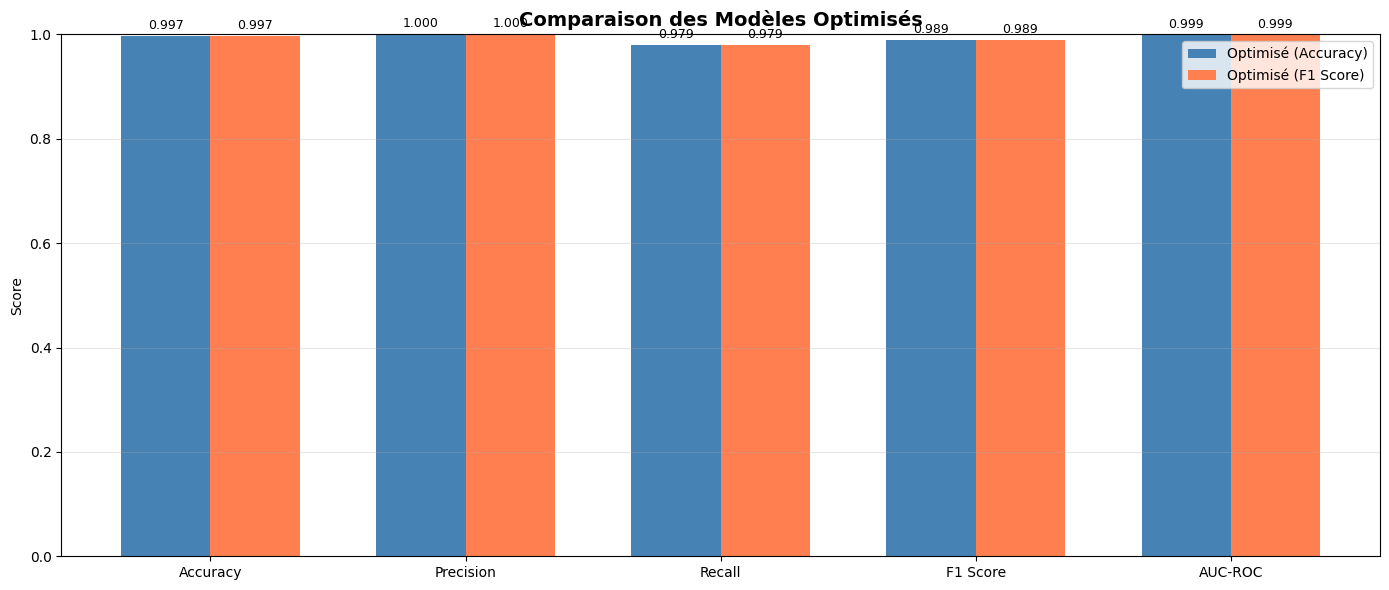

In [11]:
# Visualisation comparative
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'AUC-ROC']
x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(14, 6))
rects1 = ax.bar(x - width/2, optimization_results.iloc[0][metrics], width, label='Optimisé (Accuracy)', color='steelblue')
rects2 = ax.bar(x + width/2, optimization_results.iloc[1][metrics], width, label='Optimisé (F1 Score)', color='coral')

ax.set_ylabel('Score')
ax.set_title('Comparaison des Modèles Optimisés', fontweight='bold', fontsize=14)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.legend()
ax.set_ylim([0, 1])
ax.grid(axis='y', alpha=0.3)

# Ajouter les valeurs sur les barres
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.3f}',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=9)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
plt.savefig('Data/optimization_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## 9. Évaluation détaillée du meilleur modèle optimisé

In [12]:
# Choisir le meilleur modèle (basé sur F1 Score dans ce cas)
final_model = best_model_f1
y_pred_final = y_pred_f1
y_proba_final = y_proba_f1

print("\n" + "="*60)
print("🏆 MODÈLE FINAL OPTIMISÉ (F1 Score)")
print("="*60)
print(f"\nHyperparamètres optimaux :")
for param, value in opt_f1.best_params_.items():
    print(f"  {param:20s}: {value}")


🏆 MODÈLE FINAL OPTIMISÉ (F1 Score)

Hyperparamètres optimaux :
  bootstrap           : False
  max_depth           : 46
  max_features        : sqrt
  min_samples_leaf    : 1
  min_samples_split   : 4
  n_estimators        : 500


### 9.1 Matrice de confusion

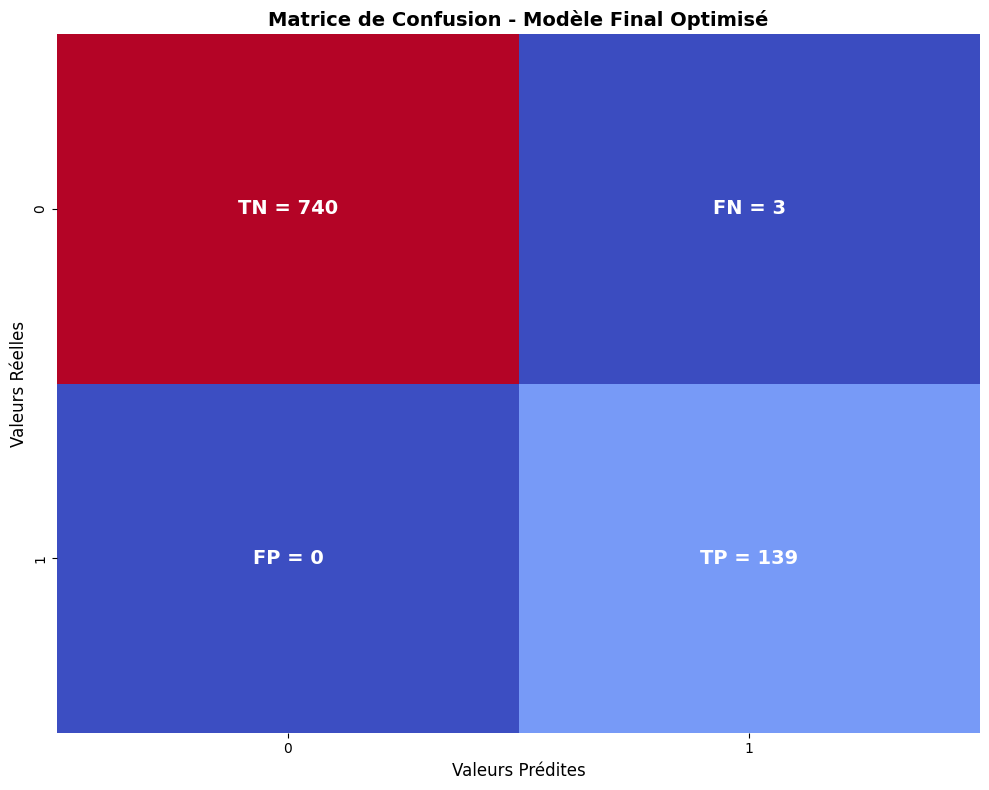


Matrice de confusion :
  True Negatives  (TN): 740
  False Positives (FP): 0
  False Negatives (FN): 3
  True Positives  (TP): 139


In [13]:
# Matrice de confusion
conf_matrix_final = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix_final, annot=False, fmt="d", cmap="coolwarm", cbar=False)

# Calcul des valeurs TP, TN, FP, FN
TN, FP, FN, TP = conf_matrix_final.ravel()

# Ajout des valeurs sur le graphique
plt.text(0.5, 0.5, f'TN = {TN}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(0.5, 1.5, f'FP = {FP}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(1.5, 0.5, f'FN = {FN}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.text(1.5, 1.5, f'TP = {TP}', ha='center', va='center', color='white', fontsize=14, fontweight='bold')
plt.title("Matrice de Confusion - Modèle Final Optimisé", fontsize=14, fontweight='bold')
plt.ylabel('Valeurs Réelles', fontsize=12)
plt.xlabel('Valeurs Prédites', fontsize=12)
plt.tight_layout()
plt.savefig('Data/final_model_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

print(f"\nMatrice de confusion :")
print(f"  True Negatives  (TN): {TN}")
print(f"  False Positives (FP): {FP}")
print(f"  False Negatives (FN): {FN}")
print(f"  True Positives  (TP): {TP}")

### 9.2 Rapport de classification

In [14]:
# Rapport de classification
print("\nRapport de Classification :")
print(classification_report(y_test, y_pred_final))


Rapport de Classification :
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       740
           1       1.00      0.98      0.99       142

    accuracy                           1.00       882
   macro avg       1.00      0.99      0.99       882
weighted avg       1.00      1.00      1.00       882



### 9.3 Courbe ROC

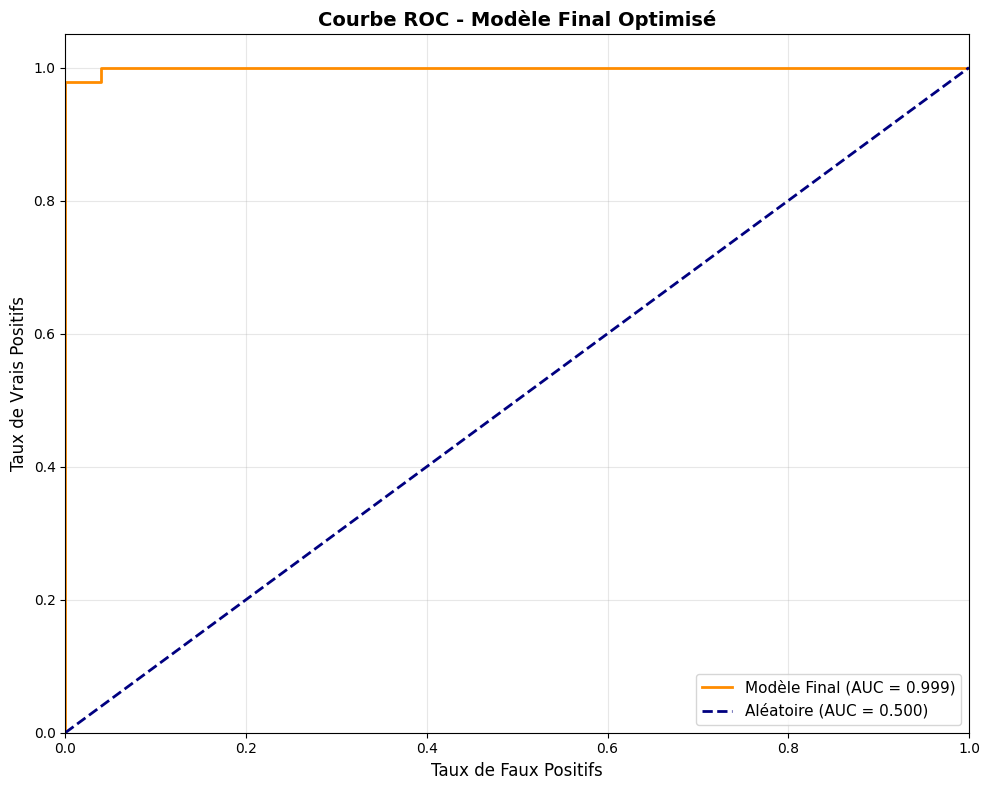

In [15]:
# Courbe ROC
fpr, tpr, thresholds = roc_curve(y_test, y_proba_final)
roc_auc = roc_auc_score(y_test, y_proba_final)

plt.figure(figsize=(10, 8))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Modèle Final (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Aléatoire (AUC = 0.500)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taux de Faux Positifs', fontsize=12)
plt.ylabel('Taux de Vrais Positifs', fontsize=12)
plt.title('Courbe ROC - Modèle Final Optimisé', fontsize=14, fontweight='bold')
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('Data/final_model_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()

### 9.4 Importance des features


Top 20 features les plus importantes :
                         feature  importance
        avg_working_time_seconds    0.108966
                             Age    0.084204
               TotalWorkingYears    0.074719
                   MonthlyIncome    0.068720
                  YearsAtCompany    0.057697
                DistanceFromHome    0.049416
               PercentSalaryHike    0.044603
            YearsWithCurrManager    0.042446
              NumCompaniesWorked    0.039719
         EnvironmentSatisfaction    0.037139
         YearsSinceLastPromotion    0.032331
                 JobSatisfaction    0.031184
           TrainingTimesLastYear    0.031070
                 WorkLifeBalance    0.029370
                       Education    0.026604
                        JobLevel    0.025648
                  JobInvolvement    0.023430
                StockOptionLevel    0.020995
BusinessTravel_Travel_Frequently    0.019081
         JobRole_Sales Executive    0.012397


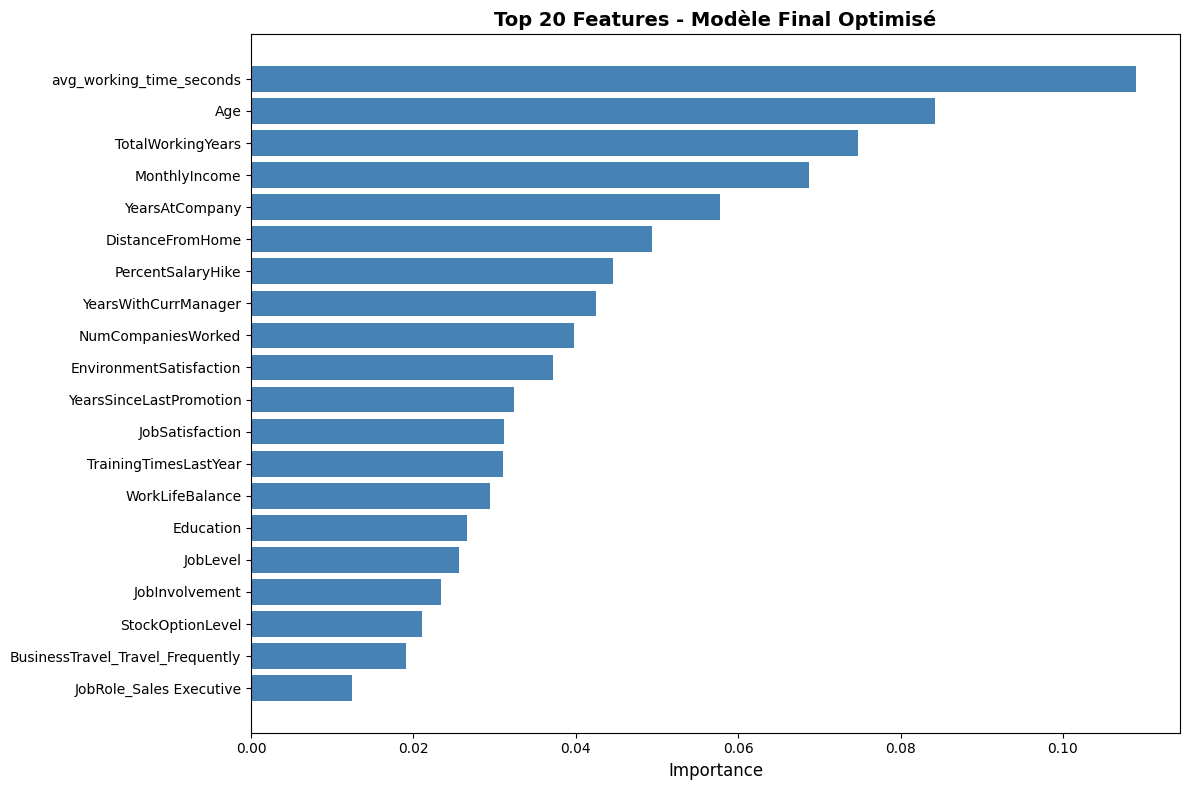

In [16]:
# Importance des features
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'importance': final_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 20 features les plus importantes :")
print(feature_importance.head(20).to_string(index=False))

# Visualisation
plt.figure(figsize=(12, 8))
plt.barh(feature_importance.head(20)['feature'], feature_importance.head(20)['importance'], color='steelblue')
plt.xlabel('Importance', fontsize=12)
plt.title('Top 20 Features - Modèle Final Optimisé', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('Data/final_model_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()

# Sauvegarder
feature_importance.to_csv('Data/final_model_feature_importance.csv', index=False)

## 10. Sauvegarde du modèle final

In [17]:
# Sauvegarder le modèle final
with open('Data/final_optimized_model.pkl', 'wb') as f:
    pickle.dump(final_model, f)

# Sauvegarder tous les résultats
final_results = {
    'model': final_model,
    'hyperparameters': opt_f1.best_params_,
    'metrics': {
        'accuracy': accuracy_score(y_test, y_pred_final),
        'precision': precision_score(y_test, y_pred_final),
        'recall': recall_score(y_test, y_pred_final),
        'f1_score': f1_score(y_test, y_pred_final),
        'auc_roc': roc_auc_score(y_test, y_proba_final)
    },
    'confusion_matrix': conf_matrix_final,
    'feature_importance': feature_importance,
    'optimization_time_f1': optimization_time_f1
}

with open('Data/final_model_results.pkl', 'wb') as f:
    pickle.dump(final_results, f)

print("\n✓ Modèle final et résultats sauvegardés!")
print("  - Data/final_optimized_model.pkl")
print("  - Data/final_model_results.pkl")


✓ Modèle final et résultats sauvegardés!
  - Data/final_optimized_model.pkl
  - Data/final_model_results.pkl


## 11. Résumé de l'optimisation

In [18]:
print("\n" + "="*60)
print("📊 RÉSUMÉ DE L'OPTIMISATION")
print("="*60)
print(f"\nModèle : Random Forest optimisé (F1 Score)")
print(f"\nTemps d'optimisation : {optimization_time_f1:.2f} secondes")
print(f"\nPerformances finales sur le test set :")
print(f"  - Accuracy  : {accuracy_score(y_test, y_pred_final):.4f}")
print(f"  - Precision : {precision_score(y_test, y_pred_final):.4f}")
print(f"  - Recall    : {recall_score(y_test, y_pred_final):.4f}")
print(f"  - F1 Score  : {f1_score(y_test, y_pred_final):.4f}")
print(f"  - AUC-ROC   : {roc_auc_score(y_test, y_proba_final):.4f}")
print(f"\nHyperparamètres optimaux :")
for param, value in opt_f1.best_params_.items():
    print(f"  - {param:20s}: {value}")
print("\n" + "="*60)


📊 RÉSUMÉ DE L'OPTIMISATION

Modèle : Random Forest optimisé (F1 Score)

Temps d'optimisation : 3675.19 secondes

Performances finales sur le test set :
  - Accuracy  : 0.9966
  - Precision : 1.0000
  - Recall    : 0.9789
  - F1 Score  : 0.9893
  - AUC-ROC   : 0.9992

Hyperparamètres optimaux :
  - bootstrap           : False
  - max_depth           : 46
  - max_features        : sqrt
  - min_samples_leaf    : 1
  - min_samples_split   : 4
  - n_estimators        : 500



## Résumé

Ce notebook a permis de :
1. Charger les données et identifier le meilleur modèle
2. Définir un espace de recherche pour les hyperparamètres
3. Effectuer une optimisation bayésienne avec deux critères (Accuracy et F1 Score)
4. Comparer les modèles optimisés
5. Évaluer en détail le modèle final optimisé
6. Analyser l'importance des features
7. Sauvegarder le modèle final prêt pour la production

Le modèle final est maintenant prêt à être utilisé pour prédire l'attrition des employés avec des performances optimisées.